# CO₂ disuelto de Zenteno con acumulación acotada

`theta_full` fijo, $C_d(0)=0$ y Csat=1.5 g/L fijo. Se recalibra únicamente kLa. Se prueba únicamente la capa de CO₂ de Zenteno adaptada para que no acumule más CO₂ del producido ni genere salida gaseosa negativa. Los límites **son una adaptación explícita**, no ecuaciones literales del paper.

Se conservan la química y las condiciones iniciales de `co2_woO2`, incluidos $X_0=0.39$ g/L en LAB016–018 (13 millones de células viables/mL); esta prueba no utiliza la inicialización alternativa de 6 millones de los ensayos eliminados. Se integran $X,N,G,F,E$ y el inventario $C_d$, sin O₂, biomasa muerta ni glicerol como estados. La pérdida de biomasa viable por muerte se conserva.

**Calibración principal:** LAB019–021; **validación:** LAB016–018. Se mantiene el orden **joint** (ajuste descriptivo con seis LAB) y **transfer** (ambas direcciones en una figura). Ninguna observación del grupo de validación entra a la calibración correspondiente. Curvas completas; figuras dentro del EXECUTED y tablas en `co2_cdZenteno_artifacts`.

**Exclusión del inicio:** las primeras 3 h de los seis LAB se conservan como contexto, pero no entran al ajuste ni a las métricas de CO₂. La simulación sigue desde t=0 con Cd(0)=0; no se reinicia en t=3 h. El preprocesamiento y los horizontes completos se conservan.

## Ecuaciones y parámetros

$$q_{\mathrm{prod}}=q_X+q_E,\qquad q_X=\frac{\mu X}{Y_{X/CO_2}},\qquad q_E=\frac{(\beta_G+\beta_F)X}{Y_{E/CO_2}}.$$

Se fijan Y_X/CO₂=12.72 g biomasa/g CO₂ y Y_E/CO₂=1.05 g etanol/g CO₂, como en la prueba previa. La producción usa tasas instantáneas; el etanol inicial no se convierte en CO₂ producido inicialmente.

$$\frac{dC_d}{dt}=\min\left\{q_{\mathrm{prod}},\;k_La\max(C_{\mathrm{sat}}-C_d,0)\right\},\qquad q_{\mathrm{gas}}=q_{\mathrm{prod}}-\frac{dC_d}{dt},\qquad C_d(0)=0.$$

El límite por producción evita acumulación sin suministro. El límite por saturación evita una tasa de acumulación negativa. Puede salir gas antes de saturarse si la producción supera la capacidad instantánea de acumulación. Esta formulación no libera posteriormente el inventario cuando cae la producción: no representa desgasificación independiente.

Se ajusta únicamente kLa, común a todos los LAB del grupo de entrenamiento; Csat se fija en 1.5 g/L en los tres ajustes. No se ajustan rendimientos, ganancia de sensor, activación por azúcar, respuesta empírica a nutrición ni theta_full. Los pulsos de N afectan la química compartida.

| Parámetro | Referencia nominal | Límites de calibración |
|---|---:|---:|
| kLa [h⁻¹] | 0.07 | 0.0001–10 |
| Csat [g/L] | **1.5 fijo** | No se calibra |

La referencia nominal utiliza kLa=0.07 h⁻¹ y el mismo Csat=1.5 g/L fijo; la curva calibrada cambia solamente kLa. Csat es constante; no se añade nuestra correlación anterior de solubilidad.

Se conserva el preprocesamiento de co2_woO2: corrección horaria chilena, señal cruda, Hampel centrado, Butterworth offline τ=30 min, temperatura 20/45 min y medianas CO₂ de diez minutos. El modelo pasa por el mismo operador de observación. Cada LAB pesa igual; por debajo de 0.05 g/L/h se aplica penalización unilateral. Los RMSE se calculan sin censura, **solo para t≥3 h**. Las muestras químicas se reservan para validación. La exclusión se aplica a los datos usados tras el filtrado; no modifica el crudo ni la dinámica simulada antes de 3 h.

La búsqueda de kLa se realiza en escala logarítmica: exploración de 61 nodos más el nominal, refinamiento acotado de los mínimos locales y comparación con ambos extremos. Se evita depender de una única inicialización.

In [1]:
from pathlib import Path
from datetime import datetime
import ast,json,sys,time,hashlib
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display,Markdown,JSON
%matplotlib inline
ROOT=Path.cwd().resolve()
while ROOT.name!='pyomo-doe' and ROOT.parent!=ROOT:ROOT=ROOT.parent
assert ROOT.name=='pyomo-doe'
assert Path(sys.prefix).name.lower()=='fermentation',sys.executable
FM=ROOT/'fermentation_model'
sys.path.insert(0,str(FM))
from shared import run_new_must_glycerol_estimability_doe as base
ND=FM/'laboratory_2026/notebooks/co2_reformulation'
OUT=ND/'co2_cdZenteno_artifacts';OUT.mkdir(exist_ok=True)
START=time.perf_counter()
Y_X_CO2=12.72
Y_E_CO2=1.05
FIXED_CSAT_G_L=1.5
PARAMETERS=('kLa_h',)
BOUNDS=((1e-4,10.),)
print('Python:',sys.executable)

Python: D:\anaconda3\envs\fermentation\python.exe


## Implementación local
La química compartida se mantiene fija. El código de acumulación acotada se incluye aquí, sin módulos auxiliares de Zenteno ni dependencia del código ejecutable de otros notebooks.

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def local_lfs_content(path, root):
    """Read an already cached LFS object without hydrating/mutating the worktree."""
    with open(path, 'rb') as handle:
        head = handle.read(200)
    if not head.startswith(b'version https://git-lfs.github.com/spec/v1'):
        return path
    lines = head.decode('ascii').splitlines()
    oid = next((line.split('sha256:', 1)[1] for line in lines if line.startswith('oid ')))
    content = Path(root) / '.git/lfs/objects' / oid[:2] / oid[2:4] / oid
    if not content.is_file():
        raise FileNotFoundError(f'Required LFS object is absent locally: {oid}')
    assert sha256(content) == oid
    return content

CORE_STATES=("X","N","G","F","E")
CORE_INDEX=[base.STATE_NAMES.index(s) for s in CORE_STATES]

def integrate_core(batch, theta, time):
    """Five active chemical states; identical shared RHS projection, exact N jumps."""

    def rhs(t, y):
        full = np.zeros(len(base.STATE_NAMES))
        full[CORE_INDEX] = y
        return np.asarray(base.rhs(t, full, theta, batch))[CORE_INDEX]
    time = np.asarray(time, float)
    state = np.array([batch.initials[s] for s in CORE_STATES])
    events = {}
    for t, dose in batch.pulses['N']:
        if time[0] <= t <= time[-1]:
            events[t] = events.get(t, 0.0) + dose
    records = {float(time[0]): state.copy()}
    current = float(time[0])
    if current in events:
        state[1] += events[current]
    for boundary in sorted({float(time[-1]), *[t for t in events if t > current]}):
        requested = time[(time > current) & (time <= boundary)]
        sol = solve_ivp(rhs, (current, boundary), state, t_eval=np.unique(np.r_[requested, boundary]), method='LSODA', rtol=2e-09, atol=2e-11, max_step=0.5)
        assert sol.success, sol.message
        records.update({float(t): y.copy() for t, y in zip(sol.t, sol.y.T)})
        state = sol.y[:, -1].copy()
        current = boundary
        if current in events:
            state[1] += events[current]
    values = np.vstack([records[float(t)] for t in time])
    assert np.isfinite(values).all() and values.min() > -1e-07
    frame = pd.DataFrame(np.maximum(values, 0.0), index=time, columns=CORE_STATES)
    frame['GF'] = frame.G + frame.F
    return frame

class Search:
    def __init__(self, root):
        self.root = Path(root)
        self.fm = self.root / 'fermentation_model'
        self.lab = self.fm / 'laboratory_2026'
        self.base = base
        self.v2 = self.lab / 'results/co2_lab016_021_recalibration_v2'
        manifest_path = self.v2 / 'manifest.json'
        self.manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
        theta_path = self.lab / 'results/estimability_historical_natural/theta_natural_full.csv'
        table = pd.read_csv(theta_path).set_index('parameter').theta.astype(float).to_dict()
        self.thetas = {'theta_full': {p: table[p] for p in base.FULL17}}
        assert self.thetas['theta_full'] == self.manifest['theta_fixed']['theta_full']
        self.theta_snapshot = self.thetas['theta_full'].copy()
        self.old = {'kLa_h': 0.07, 'Csat_g_l': 1.5}

        self.inputs = [manifest_path, theta_path, Path(base.__file__)]

        def read(name):
            p = self.v2 / name
            self.inputs.append(p)
            return pd.read_csv(p)
        self.initials = read('initial_conditions.csv').set_index('lab')
        self.obs = read('observations.csv')
        self.chem = read('chemistry_observations_corrected_YAN.csv')
        self.density = read('density_sugar_comparison/density_sugar_points.csv')
        self.biomass = read('biomass_lab016_018.csv')
        self.previous_chemistry = read('chemistry_trajectories.csv')
        self.protected = {str(p.relative_to(self.root)): sha256(p) for p in self.inputs}
        self.cores, self.cache, self.theta_by_case = ({}, {}, {})

    def verify_protected(self):
        assert self.thetas['theta_full'] == self.theta_snapshot
        assert all((sha256(self.root / p) == h for p, h in self.protected.items()))
        return len(self.protected)


def co2_rhs(cd,qprod,p):
    accumulation=min(qprod,p['kLa_h']*max(p['Csat_g_l']-cd,0.))
    return accumulation,qprod-accumulation

def bounded_pool(c,p,source_substeps=1):
    """Exact guarded dynamics for piecewise constant midpoint source; no posthoc flow repair."""
    k,cs=p['kLa_h'],p['Csat_g_l']
    time,source=c['time'],c['source']
    cd=np.zeros(len(time));qgas=np.zeros(len(time));acc=np.zeros(len(time))
    _,qgas[0]=co2_rhs(0.,source[0],p)
    for i,dt in enumerate(np.diff(time),1):
        current=cd[i-1];stored=0.;produced=0.
        step=dt/source_substeps
        for j in range(source_substeps):
            w=(j+.5)/source_substeps
            qp=source[i-1]*(1.-w)+source[i]*w
            deficit=max(cs-current,0.)
            if qp==0. or deficit==0.:
                delta=0.
            elif k*deficit<=qp:
                delta=deficit*(-np.expm1(-k*step))
            else:
                crossing=(deficit-qp/k)/qp
                linear=min(step,crossing)
                delta=qp*linear
                if crossing<step:delta+=(qp/k)*(-np.expm1(-k*(step-crossing)))
            current+=delta;stored+=delta;produced+=qp*step
        cd[i]=current
        acc[i]=stored/dt
        qgas[i]=(produced-stored)/dt
    assert qgas.min()>=-1e-12
    return qgas,cd,acc

In [3]:
"""Offline, zero-phase preprocessing and CO2 recalibration for LAB016--021.

Only local diagnostic artifacts are written by the accompanying notebook.
GUI scripts are parsed for parameters; hardware/UI code is never imported.
"""
import ast
import json
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal
from scipy.optimize import least_squares, minimize_scalar
LABS = tuple((f'LAB{i:03}' for i in range(16, 22)))
FILTERS = {'offline_20min': 1200.0, 'offline_30min': 1800.0, 'offline_40min': 2400.0}
PRIMARY = 'offline_30min'
OBS_STEP_H = 1.0 / 6.0
LOD = 0.05
QUIET = 0.02
FACTOR = 44.0095 * 60.0 * 0.74 / (1000.0 * 24.16 * 2.0)
LOCAL_ZONE = 'America/Santiago'

def local_to_utc(values):
    """Interpret logger/worksheet civil times, rejecting ambiguous/invalid times."""
    return pd.DatetimeIndex(pd.to_datetime(values)).tz_localize(LOCAL_ZONE, ambiguous='raise', nonexistent='raise').tz_convert('UTC')

def elapsed_civil_hours(hours, origin_local):
    """Convert legacy naive-clock offsets, not actual elapsed durations, to UTC."""
    wall = origin_local + pd.to_timedelta(np.asarray(hours, float), unit='h')
    return (local_to_utc(wall) - local_to_utc([origin_local])[0]).total_seconds() / 3600.0

def gui_constants(path):
    wanted = {'W_SPIKE_SECONDS', 'K', 'MIN_ABS_SPIKE', 'TAU_SECONDS', 'BUTTER_ORDER'}
    constants = {}
    for node in ast.parse(Path(path).read_text(encoding='utf-8-sig')).body:
        if isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name) and target.id in wanted:
                    constants[target.id] = ast.literal_eval(node.value)
    assert set(constants) == wanted, constants
    return constants

def centered_hampel(values, dt_s, window_s=120.0, k=3.5, floor=0.5):
    """Exact median/MAD of the same centered odd window, reflection at edges."""
    x = np.asarray(values, float)
    assert np.isfinite(x).all()
    half = max(1, int(round(window_s / (2.0 * dt_s))))
    padded = np.pad(x, (half, half), mode='reflect')
    windows = sliding_window_view(padded, 2 * half + 1)
    med = np.median(windows, axis=1)
    mad = np.median(abs(windows - med[:, None]), axis=1)
    flag = abs(x - med) > np.maximum(k * 1.4826 * mad, floor)
    return (np.where(flag, med, x), flag)

def runs(mask):
    edges = np.diff(np.r_[False, np.asarray(mask, bool), False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

def fill_short_gaps(series, max_samples):
    result = series.copy()
    candidate = series.interpolate(method='time', limit_area='inside')
    for a, b in runs(series.isna().to_numpy()):
        if b - a <= max_samples and a > 0 and (b < len(series)):
            result.iloc[a:b] = candidate.iloc[a:b]
    return result

def butter_sos(tau_s, dt_s, order=3):
    cutoff = 1.0 / (2.0 * np.pi * tau_s)
    return signal.butter(order, cutoff, fs=1.0 / dt_s, output='sos')

def zero_phase(values, tau_s, dt_s):
    padlen = min(int(np.ceil(6.0 * tau_s / dt_s)), len(values) - 2)
    assert padlen > 12 and len(values) > 24
    return signal.sosfiltfilt(butter_sos(tau_s, dt_s), values, padtype='odd', padlen=padlen)

def read_window(path, root, columns, start, end=None):
    content = local_lfs_content(path, root)
    pieces = []
    for chunk in pd.read_csv(content, usecols=columns, chunksize=400000, low_memory=False):
        stamp = pd.to_datetime(chunk.timestamp, errors='coerce')
        keep = stamp.ge(start)
        if end is not None:
            keep &= stamp.le(end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part['timestamp'] = stamp[keep]
            pieces.append(part)
    if not pieces:
        raise ValueError(f'No data in requested window: {path}')
    return (pd.concat(pieces, ignore_index=True), content)

def old_artifact_windows(raw, temp, t0):
    """Same raw excursion rule and 90-min conservative recovery used by v2."""
    state = pd.to_numeric(temp.nutricion_activa, errors='raise').astype(int)
    rising = np.flatnonzero((state.eq(1) & ~state.shift(fill_value=0).eq(1)).to_numpy())
    falling = np.flatnonzero((state.eq(0) & state.shift(fill_value=0).eq(1)).to_numpy())
    raw = raw.sort_values('timestamp')
    rtime = (raw.timestamp - t0).dt.total_seconds().to_numpy() / 3600.0
    values = raw.flow_sccm.to_numpy(float)
    rows = []
    for a in rising:
        after = falling[falling > a]
        begin = (temp.timestamp.iloc[a] - t0).total_seconds() / 3600.0
        finish = (temp.timestamp.iloc[after[0]] - t0).total_seconds() / 3600.0 if len(after) else (temp.timestamp.iloc[-1] - t0).total_seconds() / 3600.0
        pre = values[(rtime >= begin - 1.0 / 3.0) & (rtime < begin)]
        event_idx = np.flatnonzero((rtime >= begin) & (rtime <= finish + 1.0 / 30.0))
        if len(pre) < 3 or not len(event_idx):
            continue
        center = np.median(pre)
        threshold = max(3.5 * 1.4826 * np.median(abs(pre - center)), 0.5)
        crossed = event_idx[abs(values[event_idx] - center) > threshold]
        if len(crossed):
            rows.append(dict(start_h=float(rtime[crossed[0]]), end_h=float(finish + 1.5), pump_start_h=begin, pump_end_h=finish, raw_threshold_sccm=threshold))
    return rows

class ZentenoCalibration(Search):

    def __init__(self, root):
        super().__init__(root)
        self.v2_initials = self.initials.copy()
        self.v2_obs = self.obs.copy()
        self.gui_paths = [self.fm / 'context/codigo_GUI' / name for name in ('NEW_GUI_filtrado_vFINAL.py', 'NEW_GUI_filtrado_vCTORREALBA_EZO_USB.py')]
        self.gui = gui_constants(self.gui_paths[0])
        assert self.gui == gui_constants(self.gui_paths[1])
        assert self.gui == dict(W_SPIKE_SECONDS=120.0, K=3.5, MIN_ABS_SPIKE=0.5, TAU_SECONDS=1200.0, BUTTER_ORDER=3)
        self.raw_co2, self.raw_temperature, self.t0, self.artifacts = ({}, {}, {}, {})
        self.dense, self.temperature, self.observations = ({}, {}, {})
        self.filter_audit, self.coverage_rows, self.temp_audit = ([], [], [])
        self.fit_runs, self.fit_table, self.v3_fits = ([], [], {})
        self.saved_core_contexts = {}
        self.clock_audit, self.elapsed_audit, self.nutrition_events = ([], [], [])
        old_dir = self.fm / 'data/mem2026/LAB016-018'
        book_path = old_dir / 'LAB016-018-offline-measurements.xlsx'
        sheet = pd.read_excel(book_path, sheet_name='CondicionesIniciales').set_index('CodigoLab')
        recent_dir = self.fm / 'data/mem2026/LAB019-021'
        recent_t0 = pd.Timestamp('2026-09-21 17:00:00')
        recent_co2_path = recent_dir / 'backup_global_co2_completo.csv'
        recent_temp_path = recent_dir / 'backup_global_temperatura_completo.csv'
        recent_co2, cpath = read_window(recent_co2_path, self.root, ['timestamp', 'fermentador', 'flow_sccm', 'flow_filt_sccm', 'status'], recent_t0 - pd.Timedelta(hours=6))
        recent_temp, tpath = read_window(recent_temp_path, self.root, ['timestamp', 'fermentador', 'T', 'SP', 'nutricion_activa'], recent_t0 - pd.Timedelta(hours=6))
        self.extra_inputs = self.gui_paths + [recent_co2_path, recent_temp_path, cpath, tpath, self.lab / 'notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.ipynb', self.lab / 'notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.executed.ipynb']
        for i, lab in enumerate(LABS):
            fermenter = f'F{i % 3 + 1}'
            if i < 3:
                row = sheet.loc[lab]
                clock = row.Hora if hasattr(row.Hora, 'hour') else pd.to_datetime(str(row.Hora)).time()
                t0 = pd.Timestamp.combine(pd.Timestamp(row.Fecha).date(), clock)
                raw_path = old_dir / f'CO2_F{i + 1}_{lab}.csv'
                filt_path = old_dir / f'CO2_FILT_F{i + 1}_{lab}.csv'
                temp_path = old_dir / {0: 'Temp_F1_LAB016.csv', 1: 'Temp_F2_LAB017.csv', 2: 'Temp_F3._LAB018.csv'}[i]
                raw = pd.read_csv(raw_path, parse_dates=['timestamp'])
                recorded = pd.read_csv(filt_path, parse_dates=['timestamp'])
                raw = raw.merge(recorded[['timestamp', 'flow_filt_sccm']], on='timestamp', how='left', validate='one_to_one')
                tmp = pd.read_csv(temp_path, parse_dates=['timestamp'])
                self.extra_inputs += [raw_path, filt_path, temp_path]
            else:
                t0 = recent_t0
                raw = recent_co2[recent_co2.fermentador.eq(fermenter)].copy()
                tmp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            origin_local = t0
            t0 = local_to_utc([origin_local])[0]
            for kind, frame in (('co2', raw), ('temperature', tmp)):
                wall = pd.DatetimeIndex(frame.timestamp)
                utc = local_to_utc(wall)
                local_dt = wall.to_series(index=np.arange(len(wall))).diff().dt.total_seconds().to_numpy()
                real_dt = utc.to_series(index=np.arange(len(utc))).diff().dt.total_seconds().to_numpy()
                jumps = np.flatnonzero(abs(local_dt - real_dt) > 1.0)
                for j in jumps:
                    self.clock_audit.append(dict(lab=lab, signal=kind, previous_local=str(wall[j - 1]), next_local=str(wall[j]), previous_utc=str(utc[j - 1]), next_utc=str(utc[j]), civil_interval_seconds=float(local_dt[j]), elapsed_interval_seconds=float(real_dt[j])))
                frame['timestamp_local'] = frame.timestamp.astype(str)
                frame['timestamp'] = utc
            raw = raw[raw.timestamp.ge(t0 - pd.Timedelta(hours=6))].sort_values('timestamp').copy()
            tmp = tmp[tmp.timestamp.ge(t0 - pd.Timedelta(hours=6))].sort_values('timestamp').copy()
            assert raw.timestamp.is_unique and tmp.timestamp.is_unique
            raw['t_h'] = (raw.timestamp - t0).dt.total_seconds() / 3600.0
            tmp['t_h'] = (tmp.timestamp - t0).dt.total_seconds() / 3600.0
            self.t0[lab], self.raw_co2[lab], self.raw_temperature[lab] = (t0, raw, tmp)
            self.artifacts[lab] = []
            state = pd.to_numeric(tmp.nutricion_activa, errors='raise').eq(1)
            for a, b in runs(state):
                self.nutrition_events.append(dict(lab=lab, start_h=float(tmp.t_h.iloc[a]), end_h=float(tmp.t_h.iloc[min(b, len(tmp) - 1)]), excluded_from_fit=False))
            for name, frame in (('chemistry', self.chem), ('density', self.density), ('biomass', self.biomass), ('previous_chemistry', self.previous_chemistry)):
                ids = frame.index[frame.lab.eq(lab)]
                if not len(ids):
                    continue
                old = frame.loc[ids, 't_h'].to_numpy(float)
                if name == 'previous_chemistry':
                    wall = origin_local + pd.to_timedelta(old, unit='h')
                    utc = pd.DatetimeIndex(wall).tz_localize(LOCAL_ZONE, ambiguous='raise', nonexistent='NaT').tz_convert('UTC')
                    exists = ~utc.isna()
                    frame.drop(index=ids[~exists], inplace=True)
                    ids, old, utc = (ids[exists], old[exists], utc[exists])
                    new = (utc - t0).total_seconds() / 3600.0
                else:
                    new = elapsed_civil_hours(old, origin_local)
                frame.loc[ids, 't_h'] = new
                for idx, before, after in zip(ids, old, new):
                    self.elapsed_audit.append(dict(lab=lab, table=name, row=int(idx), civil_t_h=float(before), elapsed_t_h=float(after)))
            old_events = ast.literal_eval(self.initials.loc[lab, 'N_events'])
            corrected_events = tuple(((float(elapsed_civil_hours([h], origin_local)[0]), dose) for h, dose in old_events))
            self.initials.loc[lab, 'N_events'] = repr(corrected_events)
            self.initials.loc[lab, 'horizon_h'] = float(elapsed_civil_hours([self.v2_initials.loc[lab, 'horizon_h']], origin_local)[0])
        protected = set(self.extra_inputs)
        for name in ('co2_lab016_021_recalibration', 'co2_lab016_021_recalibration_v2'):
            protected.update((p for p in (self.lab / 'results' / name).rglob('*') if p.is_file()))
            protected.update((self.lab / 'notebooks/diagnostics').glob(name + '.*.ipynb'))
        protected.add(self.lab / 'notebooks/diagnostics/co2_lab016_021_recalibration_v3.source.ipynb')
        self.protected.update({str(p.relative_to(self.root)): sha256(p) for p in protected})

    def process(self):
        for lab in LABS:
            self._process_temperature(lab)
            self._process_co2(lab)
        self.filter_audit = pd.DataFrame(self.filter_audit)
        self.temp_audit = pd.DataFrame(self.temp_audit)
        self._choose_horizons()
        self.coverage = pd.DataFrame(self.coverage_rows)
        for lab in LABS:
            dense = self.dense[lab]
            cut = self.horizons[lab]
            width = OBS_STEP_H
            bin_id = np.floor(dense.time_h / width + 1e-10).astype(int)
            frame = dense.copy()
            valid = frame.valid_for_fit & frame.time_h.ge(0.0) & frame.time_h.le(cut)
            frame['bin'] = bin_id
            agg = frame[valid].groupby('bin').agg(lo=('time_h', 'min'), hi=('time_h', 'max'), n=('time_h', 'size'))
            dt = self.filter_blocks[lab][0]
            keep = (agg.hi - agg.lo >= 0.75 * width) & agg.n.ge(0.75 * width * 3600.0 / dt) & (agg.index * width >= 0.0) & ((agg.index + 1) * width <= cut + 1e-09)
            for a, b in self.fit_exclusions[lab]:
                keep &= ~((agg.index * width <= b) & ((agg.index + 1) * width >= a))
            bins = agg[keep].index
            for name in FILTERS:
                grouped = frame[valid].groupby('bin')[name].median().reindex(bins)
                points = pd.DataFrame(dict(lab=lab, bin=bins, t_h=(bins + 0.5) * width, y=grouped.to_numpy()))
                assert points.y.notna().all() and points.t_h.is_unique
                self.observations[name, lab] = points
        self.obs = pd.concat([self.observations[PRIMARY, lab] for lab in LABS], ignore_index=True)
        self.configure_temperature('reference_20_45')

    def _process_temperature(self, lab):
        raw = self.raw_temperature[lab]
        minute = raw.set_index('timestamp')[['T', 'SP']].resample('1min').median()
        minute['T'] = fill_short_gaps(minute['T'], 2)
        result = pd.DataFrame(index=minute.index)
        result['raw_1min'] = minute['T']
        for name, med, mean in (('reference_20_45', '20min', '45min'), ('strong_30_60', '30min', '60min')):
            result[name] = np.nan
            for a, b in runs(minute['T'].notna()):
                segment = minute['T'].iloc[a:b]
                filtered = segment.rolling(med, center=True, min_periods=1).median().rolling(mean, center=True, min_periods=1).mean()
                result.iloc[a:b, result.columns.get_loc(name)] = filtered.to_numpy()
            valid = result[name].notna() & result.raw_1min.notna()
            self.temp_audit.append(dict(lab=lab, variant=name, raw_std_C=float(result.loc[valid, 'raw_1min'].std()), filtered_std_C=float(result.loc[valid, name].std()), mean_change_C=float((result.loc[valid, name] - result.loc[valid, 'raw_1min']).mean()), max_change_C=float(abs(result.loc[valid, name] - result.loc[valid, 'raw_1min']).max())))
        result['SP'] = minute.SP
        result['time_h'] = (result.index - self.t0[lab]).total_seconds() / 3600.0
        self.temperature[lab] = result

    def _process_co2(self, lab):
        raw = self.raw_co2[lab]
        dt = float(raw.timestamp.diff().dt.total_seconds().median())
        assert 5.0 <= dt <= 30.0, (lab, dt)
        series = raw.set_index('timestamp')[['flow_sccm', 'flow_filt_sccm']].resample(pd.Timedelta(seconds=dt)).median()
        series.index += pd.Timedelta(seconds=dt / 2.0)
        series['flow_sccm'] = fill_short_gaps(series.flow_sccm, int(60.0 / dt))
        time = (series.index - self.t0[lab]).total_seconds().to_numpy() / 3600.0
        clean = series.flow_sccm.copy()
        frame = pd.DataFrame(dict(time_h=time, raw_sccm=series.flow_sccm.to_numpy(), recorded_sccm=series.flow_filt_sccm.to_numpy(), clean_sccm=clean.to_numpy()), index=series.index)
        frame['despiked_sccm'], frame['hampel_spike'] = (np.nan, False)
        blocks = [(a, b) for a, b in runs(clean.notna()) if b - a > 100]
        for name in FILTERS:
            frame[name] = np.nan
        for a, b in blocks:
            despiked, flag = centered_hampel(clean.iloc[a:b].to_numpy(), dt)
            frame.iloc[a:b, frame.columns.get_loc('despiked_sccm')] = despiked
            frame.iloc[a:b, frame.columns.get_loc('hampel_spike')] = flag
            for name, tau in FILTERS.items():
                frame.iloc[a:b, frame.columns.get_loc(name)] = zero_phase(despiked, tau, dt)
        baseline = (time >= 2.5) & (time <= 12.0) & frame.despiked_sccm.notna().to_numpy()
        for event in self.artifacts[lab]:
            baseline &= ~((time >= event['start_h']) & (time <= event['end_h']))
        assert baseline.sum() > 20, lab
        zero = max(0.0, float(frame.loc[baseline, 'despiked_sccm'].quantile(0.1)))
        self.fit_exclusions = getattr(self, 'fit_exclusions', {})
        guard = 0.0
        exclusions = []
        self.fit_exclusions[lab] = exclusions
        valid = frame[PRIMARY].notna().to_numpy()
        for name, tau in FILTERS.items():
            uncorrected = frame[name].to_numpy().copy()
            frame[name] = np.maximum(uncorrected - zero, 0.0) * FACTOR
            use = valid & (time >= 0.0)
            peak = int(np.nanargmax(np.where(use, frame[name], np.nan)))
            self.filter_audit.append(dict(lab=lab, variant=name, tau_s=tau, order=3, passes=2, raw_dt_s=dt, zero_sccm=zero, n_raw=len(raw), n_grid=len(frame), n_hampel=int(frame.hampel_spike.sum()), n_fit_dense=int(use.sum()), peak_g_l_h=float(frame[name].iloc[peak]), peak_h=float(time[peak]), negative_before_clipping_fraction=float(np.nanmean(uncorrected < zero)), data_start_h=float(time[0]), data_end_h=float(time[-1]), guard_h=guard))
        frame['despiked'] = np.maximum(frame.despiked_sccm - zero, 0.0) * FACTOR
        frame['recorded'] = np.maximum(frame.recorded_sccm - float(pd.read_csv(self.v2 / 'sensor_audit.csv').set_index('lab').loc[lab, 'zero_sccm']), 0.0) * FACTOR
        frame['valid_for_fit'] = valid
        self.dense[lab] = frame
        self.filter_blocks = getattr(self, 'filter_blocks', {})
        self.filter_blocks[lab] = (dt, blocks)

    def _choose_horizons(self):
        self.horizons = {}
        for lab in LABS:
            dense = self.dense[lab]
            time = dense.time_h.to_numpy()
            if lab in LABS[3:]:
                last_chem = float(self.chem[self.chem.lab.eq(lab) & ~self.chem.is_NUT].t_h.max())
            else:
                last_chem = float(max(self.density[self.density.lab.eq(lab)].t_h.max(), self.biomass[self.biomass.lab.eq(lab)].t_h.max()))
            frame = dense[dense.time_h.ge(0.0) & dense.valid_for_fit].copy()
            frame['bin'] = np.floor(frame.time_h / OBS_STEP_H).astype(int)
            ten = frame.groupby('bin')[PRIMARY].median()
            tt = (ten.index.to_numpy() + 0.5) * OBS_STEP_H
            last_active = float(tt[ten.to_numpy() >= LOD][-1]) if (ten >= LOD).any() else 0.0
            quiet_end = np.nan
            for i in range(len(ten) - 11):
                chunk = ten.iloc[i:i + 12]
                if tt[i] >= last_active and np.all(np.diff(chunk.index) == 1) and chunk.le(QUIET).all():
                    quiet_end = float((chunk.index[-1] + 1) * OBS_STEP_H)
                    break
            available = min(float(dense.time_h.max()), float(self.raw_temperature[lab].t_h.max()))
            requested = max(last_chem, quiet_end) if np.isfinite(quiet_end) else available
            cut = min(requested, available)
            assert last_chem <= available + 1e-06, (lab, last_chem, available)
            self.horizons[lab] = cut
            self.coverage_rows.append(dict(lab=lab, last_chemical_or_offline_h=last_chem, previous_v2_end_h=float(self.v2_initials.loc[lab, 'horizon_h']), raw_co2_end_h=float(self.raw_co2[lab].t_h.max()), raw_temperature_end_h=float(self.raw_temperature[lab].t_h.max()), last_detectable_CO2_h=last_active, quiet_confirmed_h=quiet_end, cut_h=cut, quiet_threshold_g_l_h=QUIET, quiet_duration_h=2.0, right_censored=not np.isfinite(quiet_end), chemistry_covered=last_chem <= cut + 1e-08))

    def configure_temperature(self, variant):
        self.cores, self.cache, self.theta_by_case = ({}, {}, {})
        self.batches = {}
        for lab in LABS:
            available = min(float(self.dense[lab].time_h.max()), float(self.raw_temperature[lab].t_h.max()))
            horizon = available
            events = ast.literal_eval(self.initials.loc[lab, 'N_events'])
            grid = np.unique(np.r_[np.arange(0.0, horizon, 1.0 / 12.0), horizon, [t for t, _ in events]])
            temp = self.temperature[lab].dropna(subset=[variant])
            assert temp.time_h.min() <= 0.0 and horizon - temp.time_h.max() <= 1.0 / 60.0 + 1e-08
            row = self.v2_initials.loc[lab]
            self.batches[lab] = self.base.BatchData(medium='natural', batch=lab, time=grid, temperature_c=np.interp(grid, temp.time_h, temp[variant]), initials={s: float(row[s]) for s in self.base.STATE_NAMES}, pulses={**{s: () for s in self.base.INPUT_CHANNELS}, 'N': events}, observations={s: np.full(len(grid), np.nan) for s in self.base.STATE_NAMES})
        self.temperature_variant = variant

    def prepare_all(self):
        for case, key in (('theta_full', 'theta_full'),):
            self.prepare(case, self.thetas[key], LABS)
        self.saved_core_contexts[self.temperature_variant] = (self.batches, self.cores, self.cache, self.theta_by_case)

    def set_context(self, name):
        self.batches, self.cores, self.cache, self.theta_by_case = self.saved_core_contexts[name]
        self.temperature_variant = name

    def chemistry_v3(self, case):
        rows = []
        for lab in LABS[3:]:
            core = self.cores[case, lab]
            data = self.chem[self.chem.lab.eq(lab) & ~self.chem.is_NUT & self.chem.t_h.gt(0.0)]
            for channel, column, mult in (('N', 'YAN_mg_l', 1000.0), ('G', 'G_g_l', 1.0), ('F', 'F_g_l', 1.0), ('GF', 'GF_g_l', 1.0), ('E', 'E_g_l', 1.0)):
                points = data[['t_h', column]].dropna()
                e = np.interp(points.t_h, core.index, core[channel] * mult) - points[column].to_numpy()
                rows.append(dict(temperature=self.temperature_variant, theta=case, lab=lab, channel=channel, n=len(points), RMSE=float(np.sqrt(np.mean(e ** 2))), bias=float(e.mean())))
        return pd.DataFrame(rows)

    def prepare(self, name, theta, labs):
        assert name == 'theta_full' and theta == self.theta_snapshot
        self.theta_by_case[name] = theta.copy()
        for lab in labs:
            bt = self.batches[lab]
            cr = integrate_core(bt, theta, bt.time)
            growth = []
            ethanol = []
            for t, row in cr.iterrows():
                terms = base.kinetic_terms(theta, base.temperature_at(bt, t), row.X, row.N, row.G, row.F, row.E)
                growth.append(terms['mu'] * row.X / Y_X_CO2)
                ethanol.append((terms['beta_g'] + terms['beta_f']) * row.X / Y_E_CO2)
            time = bt.time
            self.cores[name, lab] = cr
            self.cache[name, lab] = dict(time=time, dt=np.diff(time), source=np.array(growth) + np.array(ethanol), growth=np.array(growth), ethanol=np.array(ethanol), events=bt.pulses['N'])

    def curve(self, lab, params, source_substeps=1):
        c = self.cache['theta_full', lab]
        physical, cd, acc = bounded_pool(c, params, source_substeps)
        dense = self.dense[lab]
        t = dense.time_h.to_numpy()
        native = np.interp(t, c['time'], physical, left=0.0)
        filtered = np.full(len(t), np.nan)
        dt, blocks = self.filter_blocks[lab]
        for a, b in blocks:
            filtered[a:b] = np.maximum(zero_phase(native[a:b], FILTERS[PRIMARY], dt), 0.0)
        obs = self.observations[PRIMARY, lab]
        sampled = np.interp(obs.t_h, t, filtered)
        frame = pd.DataFrame(dict(t_h=c['time'], qprod=c['source'], q_growth=c['growth'], q_ethanol=c['ethanol'], qgas=physical, Cd=cd, accumulation=acc, CO2_observed_operator=np.interp(c['time'], t, filtered)))
        return (frame, sampled)

    def fit_layer(self, labs, label):
        labs = tuple(labs)

        def objective(log_k):
            p = {'kLa_h': float(np.exp(log_k)), 'Csat_g_l': FIXED_CSAT_G_L}
            total = 0.0
            for lab in labs:
                _, pred = self.curve(lab, p)
                y = self.observations[PRIMARY, lab].y.to_numpy()
                e = np.where(y >= LOD, pred - y, np.maximum(pred - LOD, 0.0))
                total += float(np.mean(e ** 2))
            return total
        lo, hi = np.log(BOUNDS[0])
        grid = np.unique(np.r_[np.linspace(lo, hi, 61), np.log(0.07)])
        values = np.array([objective(v) for v in grid])
        assert np.isfinite(values).all()
        candidates = [dict(x=grid[0], objective=values[0], success=True, nfev=1, method='lower_bound'), dict(x=grid[-1], objective=values[-1], success=True, nfev=1, method='upper_bound')]
        self.fit_runs.append(dict(training=label, method='log_grid', nfev=len(grid), success=True, kLa_h=float(np.exp(grid[np.argmin(values)])), Csat_g_l=FIXED_CSAT_G_L, objective=float(values.min())))
        brackets = []
        for i in range(1, len(grid) - 1):
            if values[i] <= values[i - 1] and values[i] <= values[i + 1]:
                brackets.append((grid[i - 1], grid[i + 1]))
        if values[0] <= values[1]:
            brackets.append((grid[0], grid[1]))
        if values[-1] <= values[-2]:
            brackets.append((grid[-2], grid[-1]))
        for a, b in brackets:
            sol = minimize_scalar(objective, bounds=(a, b), method='bounded', options={'xatol': 1e-08})
            row = dict(x=float(sol.x), objective=float(sol.fun), success=bool(sol.success), nfev=sol.nfev, method='bounded_refinement')
            candidates.append(row)
            self.fit_runs.append(dict(training=label, method=row['method'], success=row['success'], nfev=row['nfev'], kLa_h=float(np.exp(sol.x)), Csat_g_l=FIXED_CSAT_G_L, objective=float(sol.fun)))
        best = min(candidates, key=lambda c: c['objective'])
        p = {'kLa_h': float(np.exp(best['x'])), 'Csat_g_l': FIXED_CSAT_G_L}
        assert best['objective'] <= values.min() + 1e-08
        self.fits[label] = p
        self.fit_table.append(dict(training=label, labs=','.join(labs), **p, free_parameters='kLa_h', fixed_parameters='Csat_g_l', objective=best['objective'], success=best['success'], active_bounds='kLa_h' if min(best['x'] - lo, hi - best['x']) < 0.005 else ''))
        print(label, p, 'objective', best['objective'], flush=True)
        return p

In [4]:
V=ZentenoCalibration(ROOT);V.fits={}
V.process()

FIT_START_H=3.
V.observations_full={key:table.copy() for key,table in V.observations.items()}
for key,table in V.observations_full.items():
    V.observations[key]=table.loc[table.t_h>=FIT_START_H].copy()
V.obs=pd.concat([V.observations[PRIMARY,lab] for lab in LABS],ignore_index=True)
MASK_AUDIT=[]
for lab in LABS:
    full=V.observations_full[PRIMARY,lab]
    used=V.observations[PRIMARY,lab]
    excluded=full[full.t_h<FIT_START_H]
    assert len(excluded)==18 and len(used)>0 and used.t_h.min()>=FIT_START_H
    assert np.array_equal(used.bin.to_numpy(),full.loc[full.t_h>=FIT_START_H,'bin'].to_numpy())
    MASK_AUDIT.append(dict(lab=lab,excluded_before_h=FIT_START_H,
        n_before=len(full),n_excluded=len(excluded),n_used=len(used),first_used_h=float(used.t_h.min())))
MASK_AUDIT=pd.DataFrame(MASK_AUDIT)
display(MASK_AUDIT)

V.prepare_all()
PROTECTED_BEFORE={str(p.relative_to(ROOT)):sha256(p) for p in [ND/'co2_woO2.source.ipynb',ND/'co2_woO2.executed.ipynb']}
pd.set_option('display.max_columns',20)
display(pd.DataFrame(V.thetas).rename_axis('parameter'))
display(V.initials[[*CORE_STATES,'N_events']])
display(V.coverage)
NOMINAL={'kLa_h':.07,'Csat_g_l':FIXED_CSAT_G_L}
display(pd.DataFrame([dict(parameter='kLa_h',value=.07,status='calibrado',lower=BOUNDS[0][0],upper=BOUNDS[0][1]),
    dict(parameter='Csat_g_l',value=FIXED_CSAT_G_L,status='fijo',lower=np.nan,upper=np.nan)]))
FIGURES=0
def show(fig):
    global FIGURES
    if fig._suptitle is not None:fig._suptitle.set_y(.995)
    for legend in fig.legends:legend.set_bbox_to_anchor((.5,.95),transform=fig.transFigure)
    fig.tight_layout(rect=(0,0,1,.90));display(fig);plt.close(fig);FIGURES+=1

,lab,excluded_before_h,n_before,n_excluded,n_used,first_used_h
0,LAB016,3.0,906,18,888,3.083333
1,LAB017,3.0,846,18,828,3.083333
2,LAB018,3.0,846,18,828,3.083333
3,LAB019,3.0,996,18,978,3.083333
4,LAB020,3.0,1034,18,1016,3.083333
5,LAB021,3.0,996,18,978,3.083333


,theta_full
parameter,
mu0,0.078728
sN,8.751446
qN,0.021080
qXG,0.081491
qXF,0.070933
betaG0,0.428878
sG,0.097455
betaF0,3.440399
sF,0.178295


,X,N,G,F,E,N_events
lab,,,,,,
LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)"
LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.14), (57.1338888888888..."
LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)"
LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08),)"
LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08),)"
LAB021,0.136153,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08),)"


,lab,last_chemical_or_offline_h,previous_v2_end_h,raw_co2_end_h,raw_temperature_end_h,last_detectable_CO2_h,quiet_confirmed_h,cut_h,quiet_threshold_g_l_h,quiet_duration_h,right_censored,chemistry_covered
0,LAB016,56.184722,152.100278,151.100278,151.100000,151.083333,NaN,151.100000,0.02,2.0,True,True
1,LAB017,56.183333,152.098889,151.098889,151.098611,124.583333,141.000000,141.000000,0.02,2.0,False,True
2,LAB018,56.181389,152.096944,151.096944,151.096944,134.416667,141.000000,141.000000,0.02,2.0,False,True
3,LAB019,166.000000,166.000000,183.082222,183.085833,131.750000,144.500000,166.000000,0.02,2.0,False,True
4,LAB020,166.000000,166.000000,183.082222,183.085000,147.250000,172.333333,172.333333,0.02,2.0,False,True
5,LAB021,166.000000,166.000000,183.082222,183.085278,97.916667,111.833333,166.000000,0.02,2.0,False,True


,parameter,value,status,lower,upper
0,kLa_h,0.07,calibrado,0.0001,10.0
1,Csat_g_l,1.50,fijo,NaN,NaN


## Química fija y muestras reservadas
Mismas trayectorias que `co2_woO2`; las muestras químicas no se emplean para ajustar la capa de CO₂.

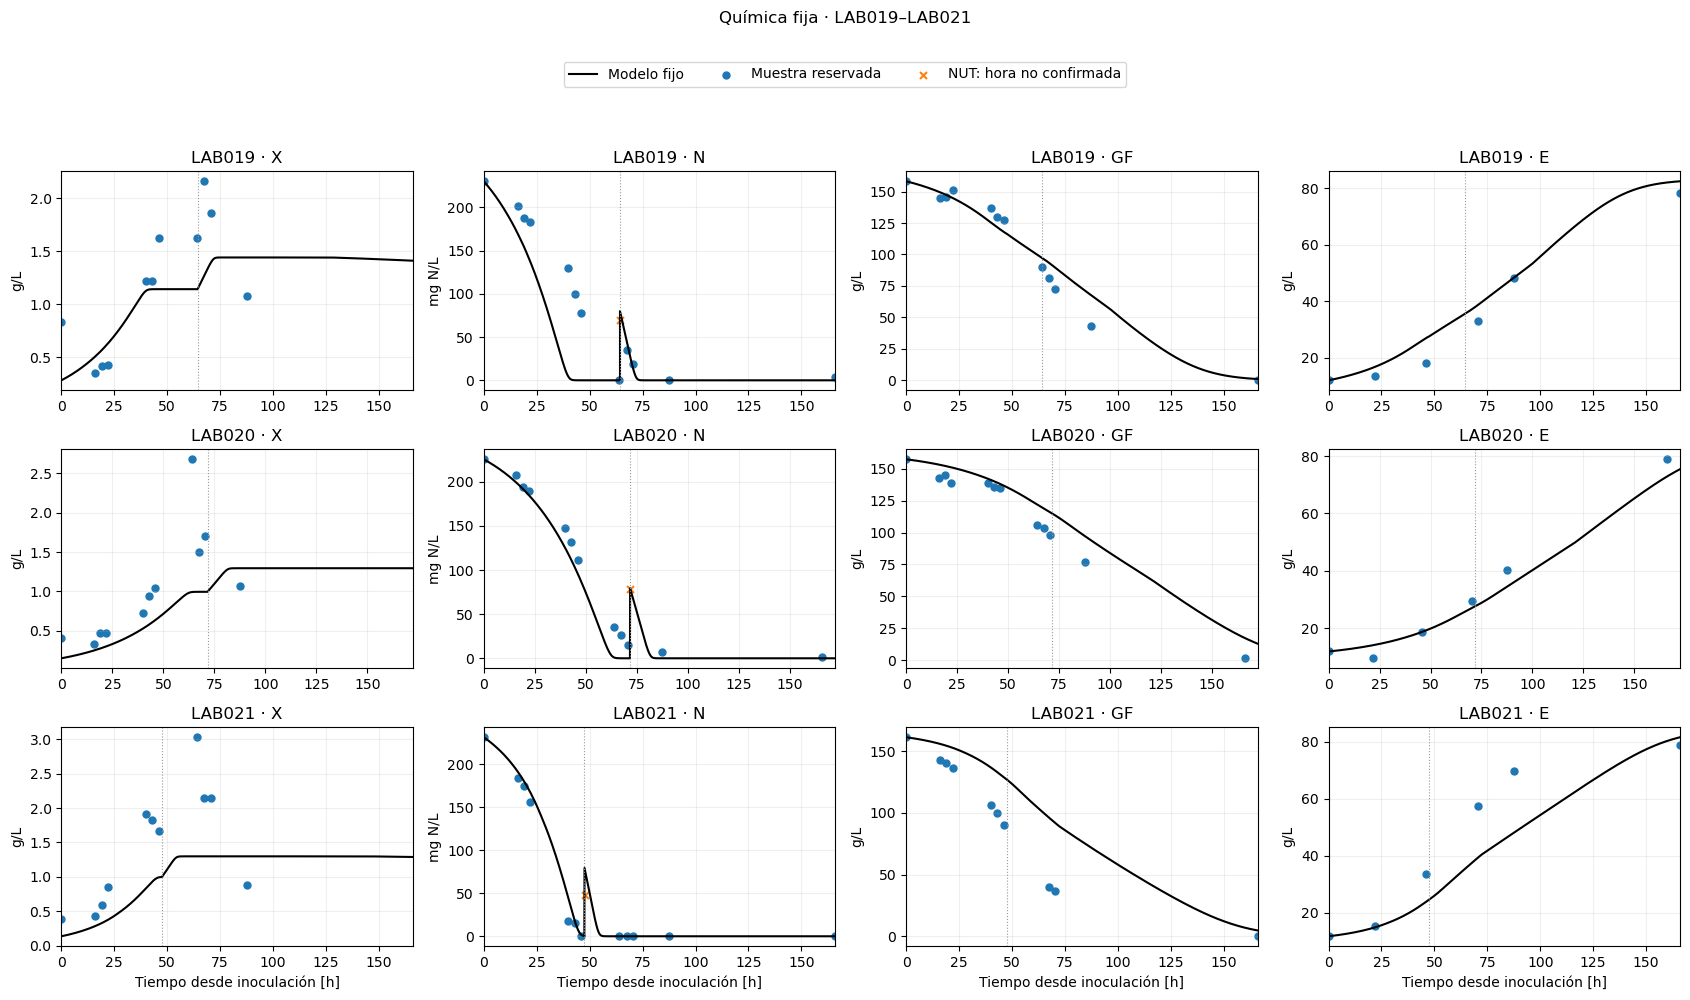

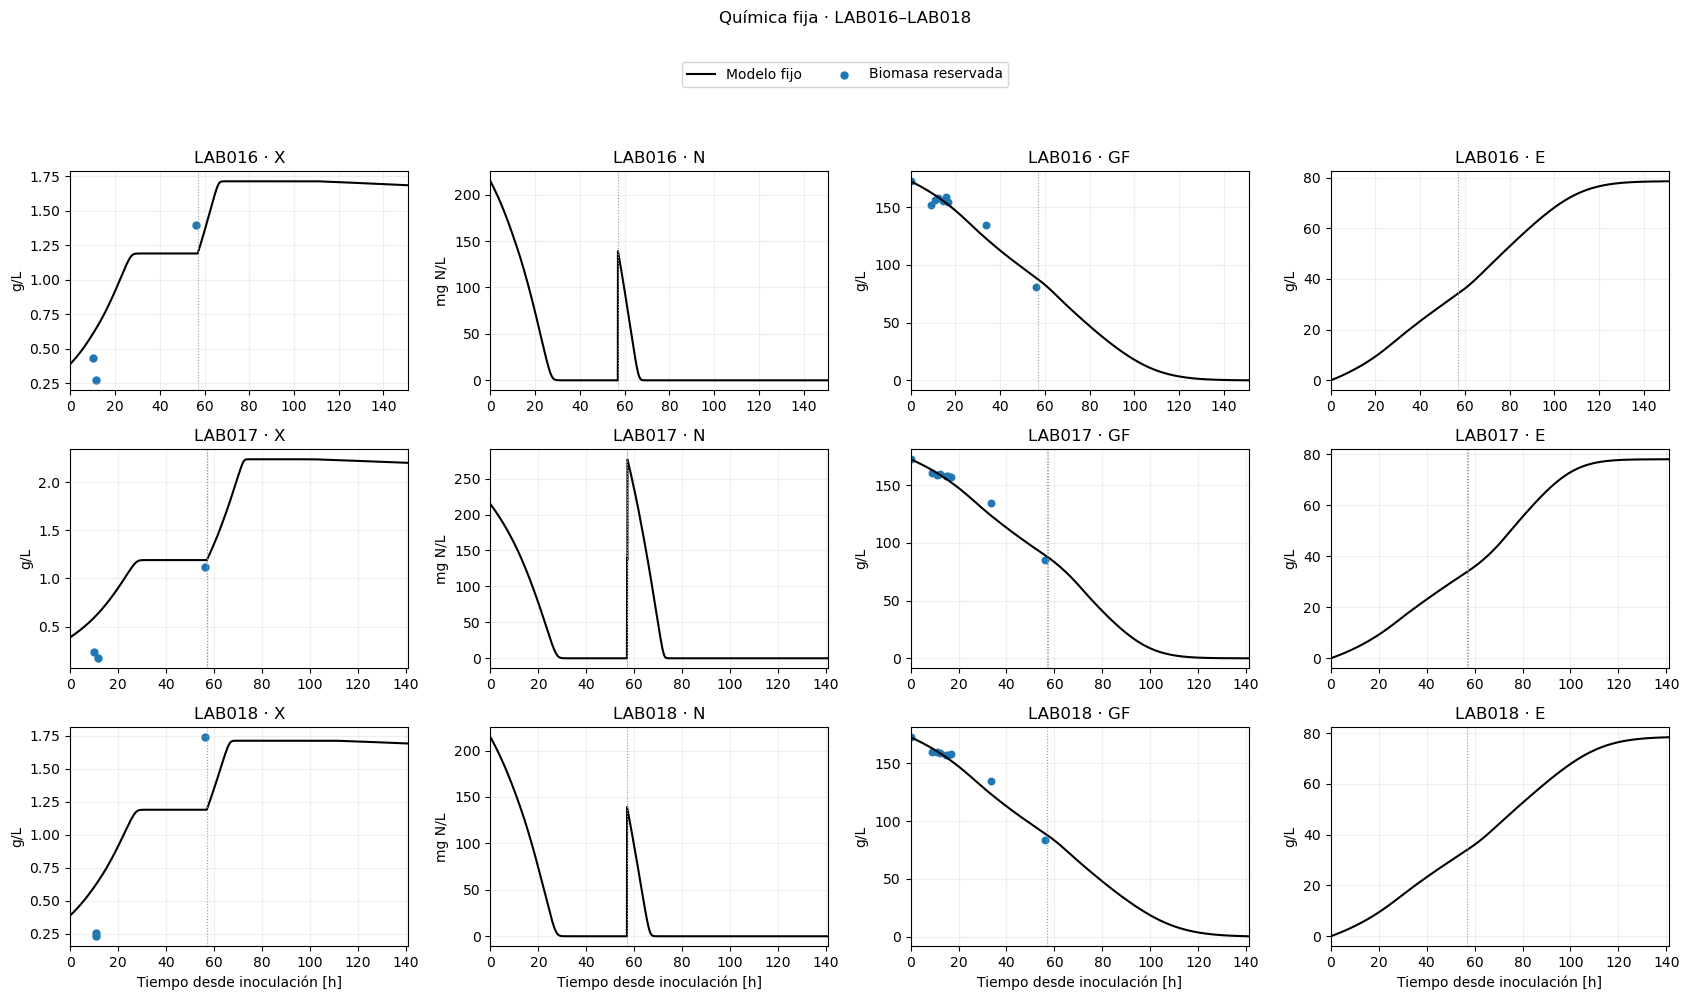

In [5]:
for cohort in (LABS[3:],LABS[:3]):
    fig,axs=plt.subplots(3,4,figsize=(17,10),sharex='row')
    for i,lab in enumerate(cohort):
        cr=V.cores['theta_full',lab];end=V.horizons[lab];cr=cr[cr.index<=end]
        for j,(ch,col,mult,unit) in enumerate([('X','X_viable_g_l',1.,'g/L'),('N','YAN_mg_l',1000.,'mg N/L'),('GF','GF_g_l',1.,'g/L'),('E','E_g_l',1.,'g/L')]):
            ax=axs[i,j];ax.plot(cr.index,cr[ch]*mult,c='black',lw=1.5,label='Modelo fijo')
            if lab in LABS[3:]:
                pts=V.chem[V.chem.lab.eq(lab)]
                if col in pts:
                    for nut,marker,label in [(False,'o','Muestra reservada'),(True,'x','NUT: hora no confirmada')]:
                        p=pts[pts.is_NUT.eq(nut)][['t_h',col]].dropna()
                        ax.scatter(p.t_h,p[col],s=25,marker=marker,label=label)
            elif ch=='X':
                p=V.biomass[V.biomass.lab.eq(lab)]
                ax.scatter(p.t_h,p.X_viable_g_l,s=25,label='Biomasa reservada')
            elif ch=='GF':
                p=V.density[V.density.lab.eq(lab)]
                # Column is resolved from the stored density calibration table.
                candidates=[c for c in p if c in ('GF_density_g_l','sugar_density_g_l','GF_from_density_g_l','sugar_g_l','GF_g_l')]
                if candidates:ax.scatter(p.t_h,p[candidates[0]],s=22,label='Azúcar por densidad')
            for t,d in V.cache['theta_full',lab]['events']:ax.axvline(t,c='.6',ls=':',lw=.8)
            ax.set(xlim=(0,end),title=f'{lab} · {ch}',ylabel=unit);ax.grid(alpha=.2)
            if i==2:ax.set_xlabel('Tiempo desde inoculación [h]')
    handles,labels=axs[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=3)
    fig.suptitle('Química fija · '+'–'.join((cohort[0],cohort[-1])),y=.99)
    show(fig)

## Calibraciones independientes
Primero joint con los seis LAB, después las calibraciones para transfer. El entrenamiento principal es LAB019–021 y su validación es LAB016–018. Se calibra solo kLa con Csat=1.5 g/L fijo y se informan convergencia y límites; el ajuste conjunto no es validación externa.

Los tres ajustes utilizan exclusivamente las observaciones con t≥3 h. La referencia nominal se evalúa sobre ese mismo soporte.

In [6]:
GROUPS={'all_six':LABS,'train_019_021':LABS[3:],'train_016_018':LABS[:3]}
for label,labs in GROUPS.items():
    V.fit_layer(labs,label)
    pd.DataFrame(V.fit_table).to_csv(OUT/'fit_parameters.csv',index=False)
FIT_TABLE=pd.DataFrame(V.fit_table);display(FIT_TABLE)
CURVES=[];METRICS=[]
for training,labs in GROUPS.items():
    for lab in LABS:
        for stage,p in [('nominal',NOMINAL),('fit',V.fits[training])]:
            cr,pred=V.curve(lab,p)
            CURVES.append(cr[cr.t_h<=V.horizons[lab]+1e-8].assign(lab=lab,training=training,stage=stage))
            obs=V.observations[PRIMARY,lab];e=pred-obs.y.to_numpy()
            peak_time=float(obs.t_h.iloc[np.argmax(obs.y.to_numpy())])
            for window,mask in [('all',np.ones(len(e),bool)),('after_peak',obs.t_h.to_numpy()>=peak_time)]:
                METRICS.append(dict(training=training,lab=lab,stage=stage,window=window,n=int(mask.sum()),
                    role='calibration' if lab in labs else 'validation',RMSE=float(np.sqrt(np.mean(e[mask]**2))),
                    bias=float(np.mean(e[mask])),peak=float(pred.max()),observed_peak=float(obs.y.max())))
CURVES=pd.concat(CURVES,ignore_index=True);METRICS=pd.DataFrame(METRICS)
display(METRICS.query('window=="all"').groupby(['training','stage','role']).RMSE.mean().to_frame())

all_six {'kLa_h': 0.0694487195751645, 'Csat_g_l': 1.5} objective 0.3909631678688252


train_019_021 {'kLa_h': 0.010175258843030558, 'Csat_g_l': 1.5} objective 0.1903507831869526


train_016_018 {'kLa_h': 0.07234878996139969, 'Csat_g_l': 1.5} objective 0.1988723495833425


,training,labs,kLa_h,Csat_g_l,free_parameters,fixed_parameters,objective,success,active_bounds
0,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",0.069449,1.5,kLa_h,Csat_g_l,0.390963,True,
1,train_019_021,"LAB019,LAB020,LAB021",0.010175,1.5,kLa_h,Csat_g_l,0.190351,True,
2,train_016_018,"LAB016,LAB017,LAB018",0.072349,1.5,kLa_h,Csat_g_l,0.198872,True,


RMSE
training      stage   role                 
all_six       fit     calibration  0.260440
              nominal calibration  0.260439
train_016_018 fit     calibration  0.259806
                      validation   0.261068
              nominal calibration  0.259820
                      validation   0.261058
train_019_021 fit     calibration  0.260401
                      validation   0.265111
              nominal calibration  0.261058
                      validation   0.259820

## CO₂ — joint y transfer
Joint muestra los seis LAB ajustados conjuntamente. Transfer usa parámetros de LAB019–021 en la fila superior (LAB016–018) y de LAB016–018 en la inferior (LAB019–021). La referencia nominal se muestra sin recalibración; las predicciones respetan los horizontes completos.

La franja gris de 0–3 h contiene el transitorio excluido: se muestra como contexto y no cuenta en ajuste ni métricas. Las curvas simuladas se conservan completas desde t=0.

Ambas curvas tienen Csat=1.5 g/L fijo. Amarilla: kLa=0.07 h⁻¹. Azul: solo kLa recalibrado en el grupo indicado.

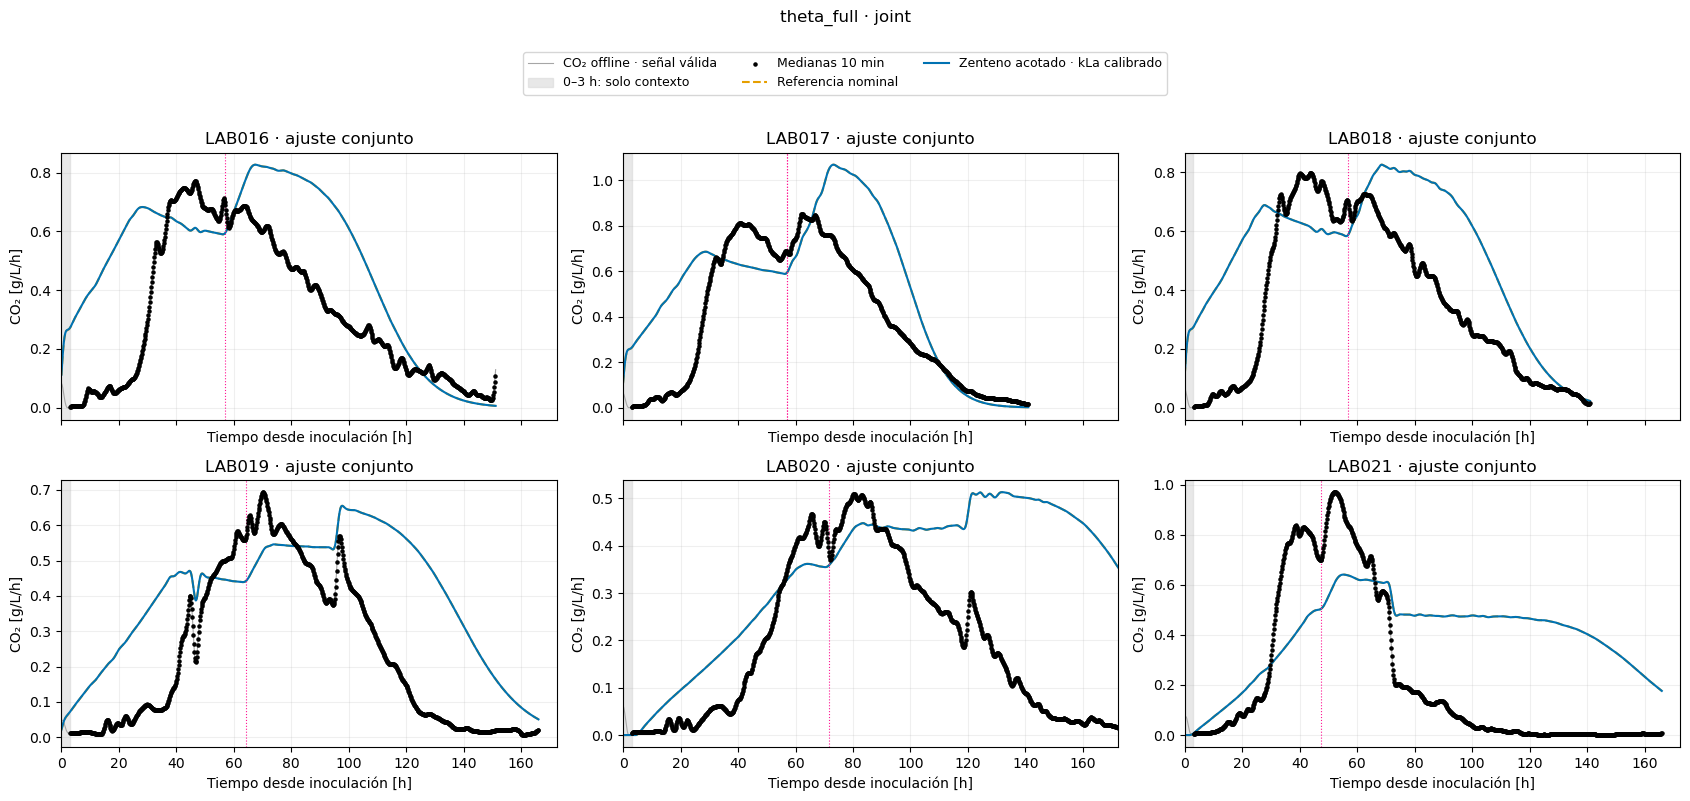

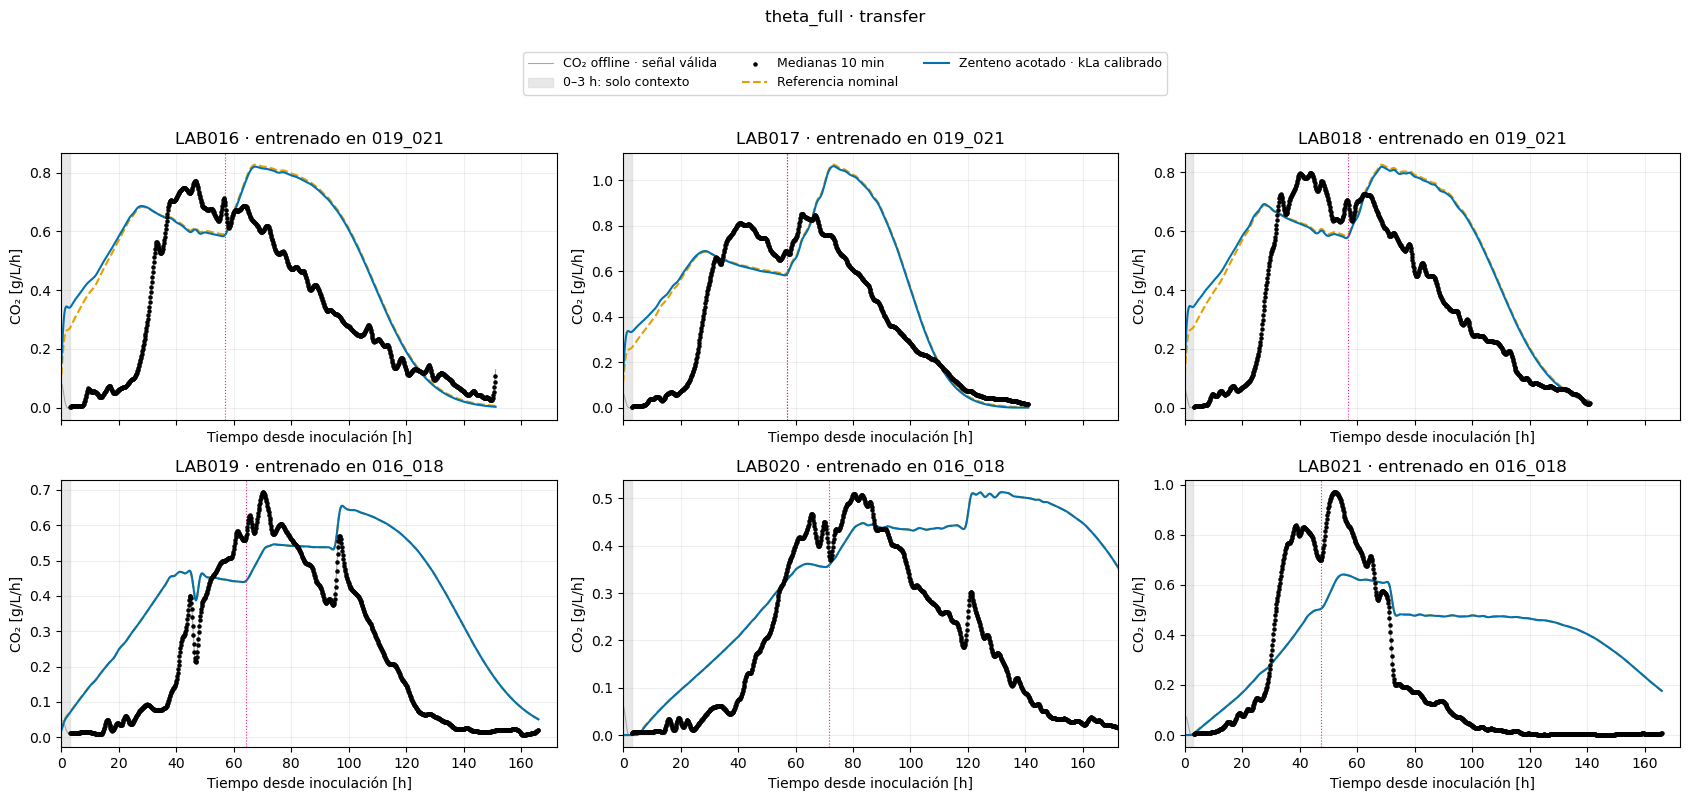

In [7]:
for kind in ('joint','transfer'):
    fig,axs=plt.subplots(2,3,figsize=(17,8),sharex='col')
    for ax,lab in zip(axs.flat,LABS):
        training='all_six' if kind=='joint' else 'train_019_021' if lab in LABS[:3] else 'train_016_018'
        dense=V.dense[lab];keep=dense.time_h.between(0.,V.horizons[lab])
        ax.plot(dense.time_h[keep],np.where(dense.valid_for_fit,dense[PRIMARY],np.nan)[keep],c='.65',lw=.8,label='CO₂ offline · señal válida')
        ax.axvspan(0.,FIT_START_H,color='.85',alpha=.6,label='0–3 h: solo contexto')
        obs=V.observations[PRIMARY,lab];ax.scatter(obs.t_h,obs.y,c='black',s=5,label='Medianas 10 min',zorder=5)
        for stage,color,ls,label in [('nominal','#E69F00','--','Referencia nominal'),('fit','#0072B2','-','Zenteno acotado · kLa calibrado')]:
            cr=CURVES.query('lab==@lab and training==@training and stage==@stage')
            ax.plot(cr.t_h,cr.CO2_observed_operator,c=color,ls=ls,label=label)
        for t,dose in V.cache['theta_full',lab]['events']:ax.axvline(t,c='deeppink',ls=':',lw=.8)
        ax.set(title=f'{lab} · '+('ajuste conjunto' if kind=='joint' else f'entrenado en {training[6:]}'),
            xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/L/h]',xlim=(0.,max(V.horizons.values())))
        ax.grid(alpha=.2)
    fig.legend(*axs[0,0].get_legend_handles_labels(),loc='upper center',ncol=3,fontsize=9)
    fig.suptitle('theta_full · '+kind);show(fig)

## Acumulación, producción y liberación
Parámetros calibrados exclusivamente con LAB019–021. Se representa el inventario disuelto y la partición entre acumulación y salida; no hay mediciones de CO₂ disuelto para validar directamente el inventario.

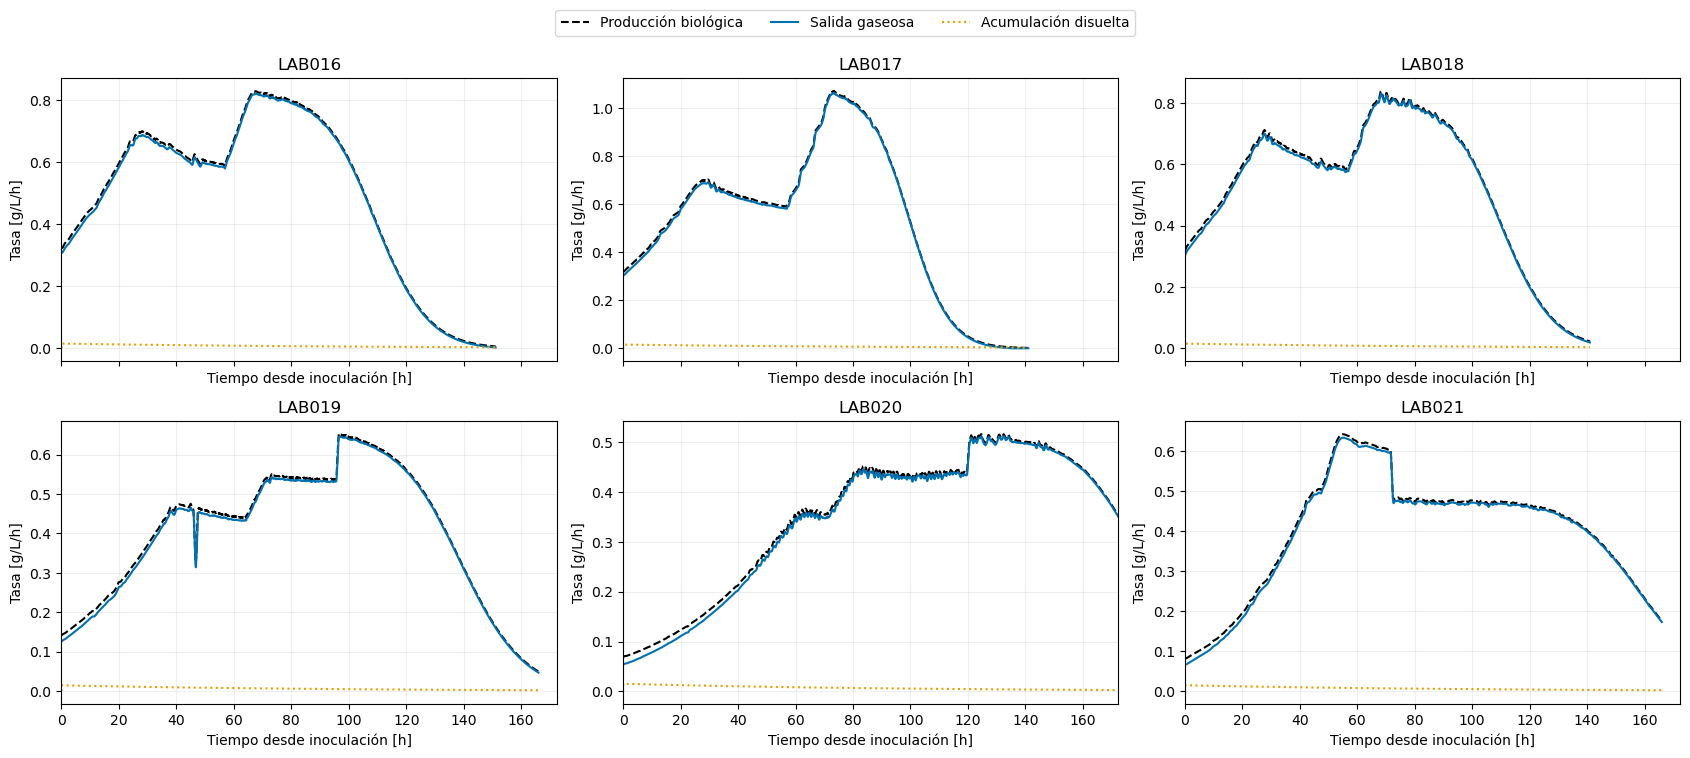

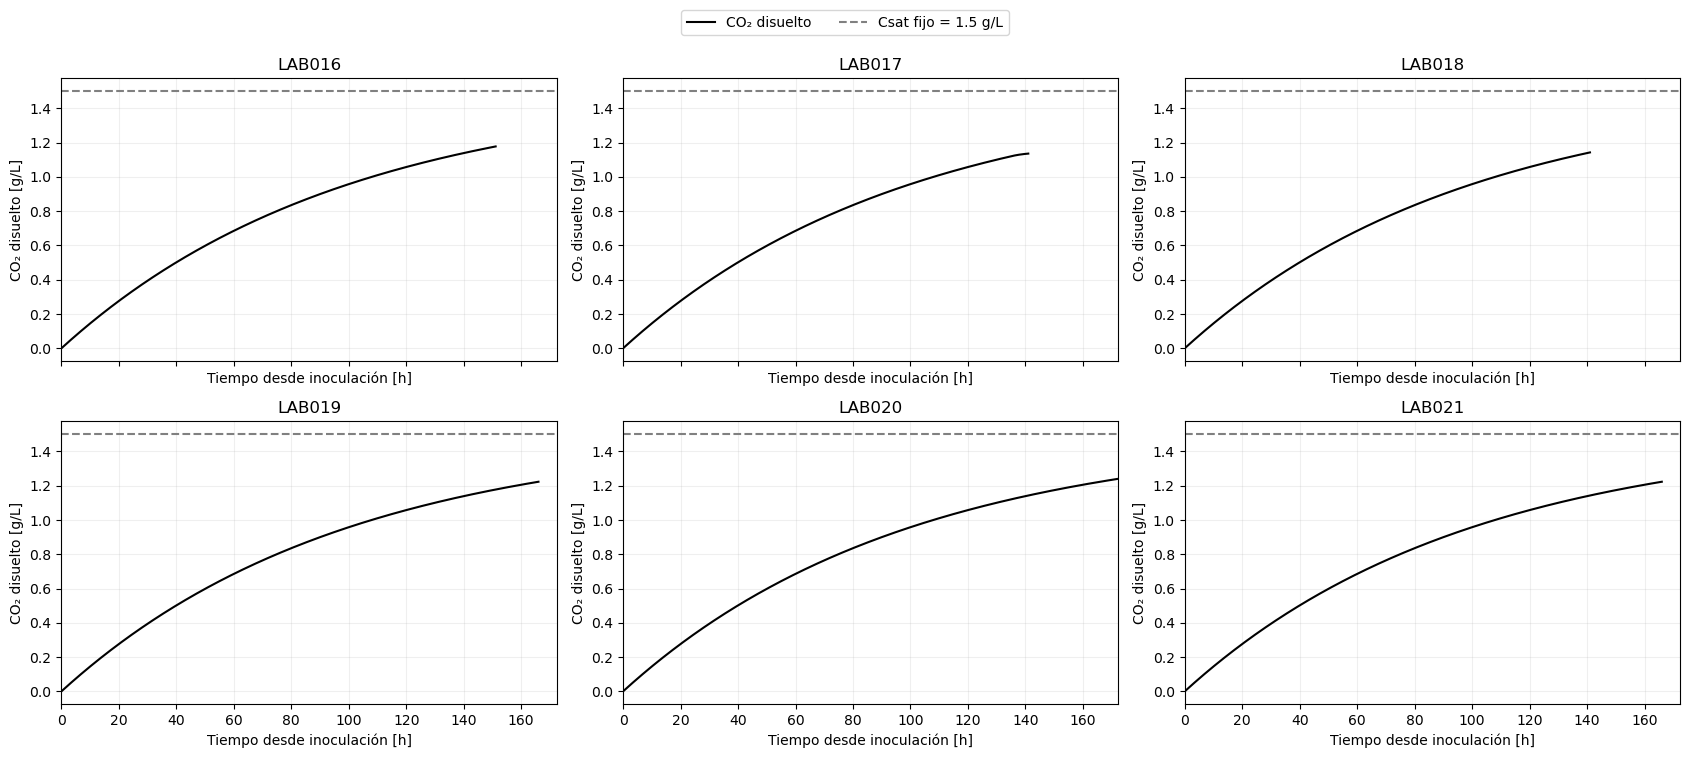

In [8]:
for quantity in ('rates','dissolved'):
    fig,axs=plt.subplots(2,3,figsize=(17,8),sharex='col')
    for ax,lab in zip(axs.flat,LABS):
        cr=CURVES.query('training=="train_019_021" and stage=="fit" and lab==@lab')
        if quantity=='rates':
            ax.plot(cr.t_h,cr.qprod,c='black',ls='--',label='Producción biológica')
            ax.plot(cr.t_h,cr.qgas,c='#0072B2',label='Salida gaseosa')
            ax.plot(cr.t_h,cr.accumulation,c='#E69F00',ls=':',label='Acumulación disuelta')
            ax.set_ylabel('Tasa [g/L/h]')
        else:
            ax.plot(cr.t_h,cr.Cd,c='black',label='CO₂ disuelto')
            ax.axhline(V.fits['train_019_021']['Csat_g_l'],c='.5',ls='--',label='Csat fijo = 1.5 g/L')
            ax.set_ylabel('CO₂ disuelto [g/L]')
        ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',xlim=(0.,max(V.horizons.values())));ax.grid(alpha=.2)
    fig.legend(*axs[0,0].get_legend_handles_labels(),loc='upper center',ncol=3)
    show(fig)

## Verificaciones y resultados
Se comprueban conservación, cotas, salida no negativa, convergencia con subdivisión temporal, paridad química y observaciones idénticas al notebook anterior en el soporte retenido t≥3 h. Se contrasta además la solución por intervalos con la integración directa de la ecuación acotada. La saturación no obliga a esperar hasta llenarse para liberar gas.

In [9]:
# Independent integration of guarded ODE for representative constant supplies.
for qp in (0.,.005,.05,.5):
    t=np.linspace(0.,80.,801)
    driver=dict(time=t,source=np.full(len(t),qp))
    gas,cd,acc=bounded_pool(driver,NOMINAL)
    sol=solve_ivp(lambda t,y:[co2_rhs(y[0],qp,NOMINAL)[0]],(0.,80.),[0.],t_eval=t,rtol=1e-10,atol=1e-12,max_step=.05)
    assert np.max(abs(cd-sol.y[0]))<1e-7
    assert np.max(abs(np.cumsum(np.r_[0.,gas[1:]*np.diff(t)])+cd-qp*t))<1e-10
CHECKS=[]
for training,p in V.fits.items():
    for lab in LABS:
        assert p['Csat_g_l']==FIXED_CSAT_G_L
        c=V.cache['theta_full',lab];gas,cd,acc=bounded_pool(c,p)
        qp=(c['source'][:-1]+c['source'][1:])/2.
        err=float(np.max(abs(np.diff(cd)-c['dt']*(qp-gas[1:]))))
        assert err<1e-10 and gas.min()>=-1e-12 and cd.min()>=0.
        assert cd.max()<=p['Csat_g_l']+1e-10
        row=dict(training=training,lab=lab,mass_balance_error=err,minimum_qgas=float(gas.min()),maximum_Cd=float(cd.max()))
        if training=='train_019_021':
            cr,pred=V.curve(lab,p);fine,pred_fine=V.curve(lab,p,source_substeps=4)
            row['refinement_max']=float(np.max(abs(pred-pred_fine)))
            assert row['refinement_max']<.01
        CHECKS.append(row)
CHECKS=pd.DataFrame(CHECKS);display(CHECKS)
old=ND/'co2_woO2_artifacts'
old_obs=pd.read_csv(old/'observations_10min.csv').query('t_h>=@FIT_START_H').sort_values(['lab','t_h'])
OBS=pd.concat([V.observations[PRIMARY,l] for l in LABS],ignore_index=True).sort_values(['lab','t_h'])
assert OBS.t_h.min()>=FIT_START_H
assert all(c['time'][0]==0. for c in V.cache.values())
assert list(old_obs.lab)==list(OBS.lab)
assert np.max(abs(old_obs.t_h.to_numpy()-OBS.t_h.to_numpy()))<1e-8
assert np.max(abs(old_obs.y.to_numpy()-OBS.y.to_numpy()))<1e-10
old_chem=pd.read_csv(old/'chemistry_trajectories.csv')
CHEM_PARITY=[]
for lab in LABS:
    cr=V.cores['theta_full',lab];o=old_chem[old_chem.lab.eq(lab)]
    assert np.max(abs(o.t_h.to_numpy()-cr.index.to_numpy()[:len(o)]))<1e-8
    error=float(np.max(abs(o[list(CORE_STATES)].to_numpy()-cr[list(CORE_STATES)].iloc[:len(o)].to_numpy())))
    assert error<1e-8
    CHEM_PARITY.append(dict(lab=lab,max_absolute_error=error))
assert FIT_TABLE.success.all()
assert V.verify_protected()>0
assert all(sha256(ROOT/p)==h for p,h in PROTECTED_BEFORE.items())
for name,df in [('fit_parameters',FIT_TABLE),('optimizer_runs',pd.DataFrame(V.fit_runs)),('metrics',METRICS),
    ('gas_trajectories',CURVES),('observations_10min',OBS),('coverage',V.coverage),('initial_conditions',V.initials.reset_index()),
    ('observation_mask_audit',MASK_AUDIT),
    ('excluded_observations_10min',pd.concat([table.loc[table.t_h<FIT_START_H] for (filtering,lab),table in V.observations_full.items() if filtering==PRIMARY],ignore_index=True)),
    ('checks',CHECKS),('chemistry_parity',pd.DataFrame(CHEM_PARITY)),('chemistry_metrics',V.chemistry_v3('theta_full'))]:
    df.to_csv(OUT/(name+'.csv'),index=False)
pd.concat([cr[cr.index<=V.horizons[lab]].rename_axis('t_h').reset_index().assign(lab=lab) for (case,lab),cr in V.cores.items()],ignore_index=True).to_csv(OUT/'chemistry_trajectories.csv',index=False)
display(Markdown('**Resultado principal — ajuste en LAB019–021:**'))
display(pd.DataFrame([V.fits['train_019_021']]))
for role in ('calibration','validation'):
    m=METRICS.query('training=="train_019_021" and stage=="fit" and window=="all" and role==@role')
    display(Markdown(f'RMSE medio de {role}: **{m.RMSE.mean():.4f} g/L/h**.'))
display(Markdown('Los parámetros son efectivos dentro de esta formulación y de la química fija. Un ajuste de CO₂ no corrige discrepancias de azúcar, etanol o biomasa. Csat se ha fijado, no identificado. La exploración global de kLa y sus límites activos describen el ajuste condicionado a esta saturación.'))
TRACEABILITY=dict(created_at=datetime.now().astimezone().isoformat(),python=sys.executable,
    source_sha256=sha256(ND/'co2_cdZenteno.source.ipynb'),theta_fixed=V.theta_snapshot,Cd0=0.,
    layer='Zenteno production and dissolved CO2; explicit min/max adaptation',yields=dict(Y_X_CO2=Y_X_CO2,Y_E_CO2=Y_E_CO2),
    initial_X_LAB016_018_g_l=.39,parameters=PARAMETERS,bounds=BOUNDS,fixed_Csat_g_l=FIXED_CSAT_G_L,sensor_gain=1.,
    excluded_before_h=FIT_START_H,fit_and_metrics='t>=3 h; all six LAB',simulation_start_h=0.,mask_audit=MASK_AUDIT.to_dict('records'),
    primary_filter=PRIMARY,temperature='reference_20_45',main_training=LABS[3:],main_validation=LABS[:3],
    input_sha256=V.protected,previous_notebooks_sha256=PROTECTED_BEFORE,figures_inline=FIGURES,
    elapsed_seconds=time.perf_counter()-START)
display(JSON(TRACEABILITY,expanded=False))
print('Ejecución y verificaciones completadas; segundos:',round(time.perf_counter()-START,1))

,training,lab,mass_balance_error,minimum_qgas,maximum_Cd,refinement_max
0,all_six,LAB016,1.188082e-16,0.005920,1.499958,NaN
1,all_six,LAB017,1.189607e-16,0.000262,1.499958,NaN
2,all_six,LAB018,1.189607e-16,0.006349,1.499958,NaN
3,all_six,LAB019,1.182390e-16,0.009646,1.499995,NaN
4,all_six,LAB020,1.159830e-16,0.000000,1.499995,NaN
5,all_six,LAB021,1.167415e-16,0.000000,1.499995,NaN
6,train_019_021,LAB016,1.116186e-16,0.002642,1.177617,4.306555e-13
7,train_019_021,LAB017,1.116186e-16,0.000000,1.143086,5.452796e-08
8,train_019_021,LAB018,1.133533e-16,0.003072,1.177607,5.613288e-13
9,train_019_021,LAB019,1.171480e-16,0.007277,1.267169,5.333511e-13


**Resultado principal — ajuste en LAB019–021:**

,kLa_h,Csat_g_l
0,0.010175,1.5


RMSE medio de calibration: **0.2604 g/L/h**.

RMSE medio de validation: **0.2651 g/L/h**.

Los parámetros son efectivos dentro de esta formulación y de la química fija. Un ajuste de CO₂ no corrige discrepancias de azúcar, etanol o biomasa. Csat se ha fijado, no identificado. La exploración global de kLa y sus límites activos describen el ajuste condicionado a esta saturación.

<IPython.core.display.JSON object>

Ejecución y verificaciones completadas; segundos: 49.1
